# **Aula 7 - Estatística Inferencial**<font size=3>

## **1. Preparando os dados**<font size=3>

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="colorblind")

Iniciou-se a aula com a importação das bibliotecas necessárias para a simulação, testes e visualização.

In [55]:
mtcars = (
    pd.read_csv("/content/drive/MyDrive/UFRN/Datasets/mtcars.csv")
    .assign(
        transmission=lambda df: np.where(
            df["am"] == 1,
            "Manual",
            "Automático",
        ),
    )
)

mtcars.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,transmission
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4,Manual
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4,Manual
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1,Manual
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1,Automático
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2,Automático


Uma coluna auxiliar com rótulo legível foi criada para indicar se o carro da amostra é manual ou automático.

## **2. A diferença observada**<font size=3>

Diferença observada é uma estatística que, normalmente, com o uso da média, serve para representar a distância entre grupos distintos.

In [56]:
(
    mtcars
    .groupby("transmission")
    .mpg
    .agg(["size", "mean", "median", "std"])
    .round(2)
)

,size,mean,median,std
transmission,,,,
Automático,19,17.15,17.3,3.83
Manual,13,24.39,22.8,6.17


Um resumo com o total, média, mediana e desvio-padrão de carros da categoria automático e manual foi gerado. A partir dele, é possível inferir algumas coisas, como o fato de que os grupos tem tamanhos diferentes, a média e mediana nos carros manuais indica que alguns carros mais econômicos puxam a média para cima e que os carros com câmbio manual são mais diversificados.

In [57]:
manual = mtcars.loc[mtcars.am == 1, "mpg"]
automatic = mtcars.loc[mtcars.am == 0, "mpg"]

delta_obs = manual.mean() - automatic.mean()

round(delta_obs, 2)

np.float64(7.24)

Calculando a diferença observada entre os grupos de carros manuais e automáticos, constata-se que o câmbioo manual faz, em média, 7,24 milhas por galão a mais, sendo assim, são mais econômicos.

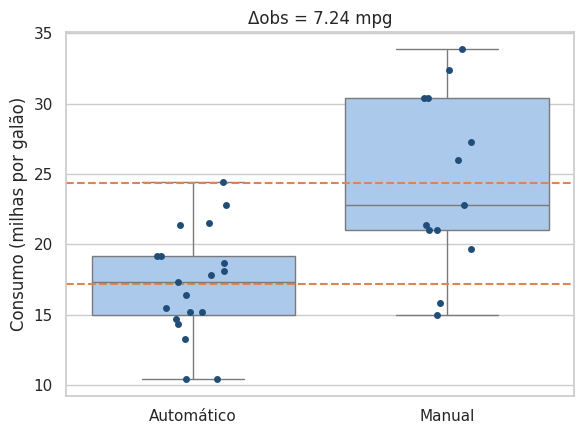

In [58]:
def plot_groups(data, x, y, order, ax, alpha=1, jitter=.15):
    sns.boxplot(
        data=data, x=x, y=y, order=order, ax=ax,
        color="#A1C9F4",
        showfliers=False,
    )
    sns.stripplot(
        data=data, x=x, y=y, order=order, ax=ax,
        color="#1F4E79", alpha=alpha, jitter=jitter,
    )

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_groups(mtcars, "transmission", "mpg", ["Automático", "Manual"], ax)
for mean in [automatic.mean(), manual.mean()]:
    ax.axhline(mean, color="#DD8452", linestyle="--")
ax.set(title=f"Δobs = {delta_obs:.2f} mpg", xlabel="",
       ylabel="Consumo (milhas por galão)")
plt.tight_layout()
plt.show()

O boxplot acima confirma a maior eficiência em carros manuais, contudo, atenta-se que existem exceções que consomem o mesmo que um carro automático típico, além de que também existem alguns automáticos tão eficientes quanto a média no grupo dos manuais.

Mesmo com um valor diferente de zero, a diferença é apenas uma descrição da amostra, sendo necessário ter cautela pelos três motivos a seguir:


*   Natureza estocástica relembra que uma amostra não define o aspecto geral e é apenas uma entre diversas realizações possíveis;
*   A diferença observada usa a média, tornando-se sensível a valores atípicos;
*   O recorte limitado pega apenas uma janela no espaço e tempo.


## **3. O problema da aleatoriedade**<font size=3>

Apofenia é um dos principais problemas da aleatoriedade, sendo a tendência humana de perceber padrões e relações significativas em dados puramente aleatórios. Um exemplo seria a crença de que “plantão de lua cheia é sempre cheio”.

### **3.1. Um pronto-socorro simulado**<font size=3>

In [59]:
rng = np.random.default_rng(2726)

full_moon_days = np.round(np.arange(12) * 29.53 + 14)

er_visits = (
    pd.DataFrame({"day": np.arange(365)})
    .assign(
        visits=rng.poisson(120, size=365),
        full_moon=lambda df: df["day"].isin(full_moon_days),
        moon=lambda df: np.where(df["full_moon"], "Lua cheia", "Demais dias"),
    )
)

Para estudar a creça citada, dados de um ano de atendimentos em um pronto-socorro fictício foram simulados e sorteados da mesma distribuição, sendo assim, qualquer diferença que encontrarmos entre os grupos terá sido produzida apenas pelo acaso.

In [60]:
(
    er_visits
    .groupby("moon")
    .visits
    .agg(["size", "mean", "median", "std"])
    .round(2)
)

,size,mean,median,std
moon,,,,
Demais dias,353,119.78,119.0,10.94
Lua cheia,12,123.67,121.5,9.36


Nos dados gerados, a média e mediana manteve-se superior nos dias de lua cheia, contudo, ao observar o desvio-padrão, é importante destacar que as estatísticas definidas nos demais dias é muito mais estável, devido a quantidade total de amostras, do que as existentes nos poucos dias de lua cheia que oscilam bastante.

In [61]:
moon_in = er_visits.loc[er_visits.full_moon, "visits"]
moon_out = er_visits.loc[~er_visits.full_moon, "visits"]

moon_obs = moon_in.mean() - moon_out.mean()

round(moon_obs, 2)

np.float64(3.88)

A diferença observada entre os dois grupos é de 3.88, confirmando a crença.

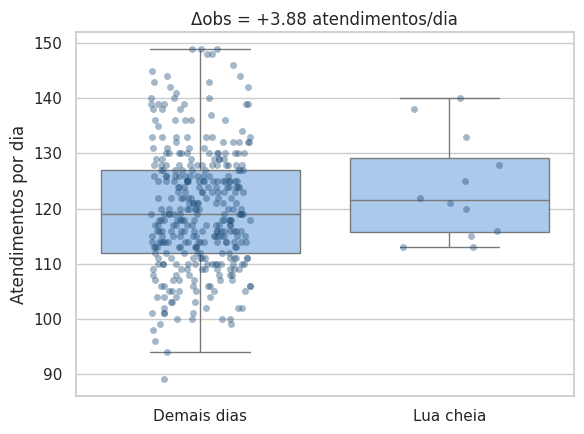

In [62]:
fig, ax = plt.subplots(figsize=(6, 4.5))

plot_groups(
    er_visits, "moon", "visits", ["Demais dias", "Lua cheia"], ax,
    alpha=.4, jitter=.2,
)

ax.set(
    title=f"Δobs = {moon_obs:+.2f} atendimentos/dia",
    xlabel="",
    ylabel="Atendimentos por dia",
)

plt.tight_layout()
plt.show()

Mesmo com um valor positivos, ao criar um boxplot do caso, percebe-se que as distribuições se sobrepõem quase inteiramente.

## **4. Formalizando o acaso**<font size=3>

### **4.1. Hipóteses nula e alternativa**<font size=3>

Um teste de hipóteses confronta duas proposições sobre a população, a nula afirma não existir efeito e que a diferença observada é fruto do acaso, enquanto a alternativa afirma o efeito real no processo gerador dos dados.

### **4.2. O teste de permutação**<font size=3>

Caso a hipótese nula seja verdadeira, os rótulos tornam-se intercambiáveis. Sendo assim, para verificar isso, é necessário realizar quatro passos: medir a estatística nos dados reais, embaralhar as amostras, recalcular os valores e repetir isso diversas vezes.

In [63]:
def permutation_null(values, labels, n_perm=10_000, seed=2026):
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        shuffled = rng.permutation(labels)
        null.append(values[shuffled].mean() - values[~shuffled].mean())
    return np.array(null)

moon_values = er_visits["visits"].to_numpy()
moon_labels = er_visits["full_moon"].to_numpy()

moon_null = permutation_null(moon_values, moon_labels)

moon_null[:5].round(2)

array([-5.33, -6.46, -2.23, -1.54,  4.49])

Os valores no array acima mostram a diferença observada que o acaso produz, ou seja, se 12 dias quaisquer recebessem o rótulo de lua cheia.

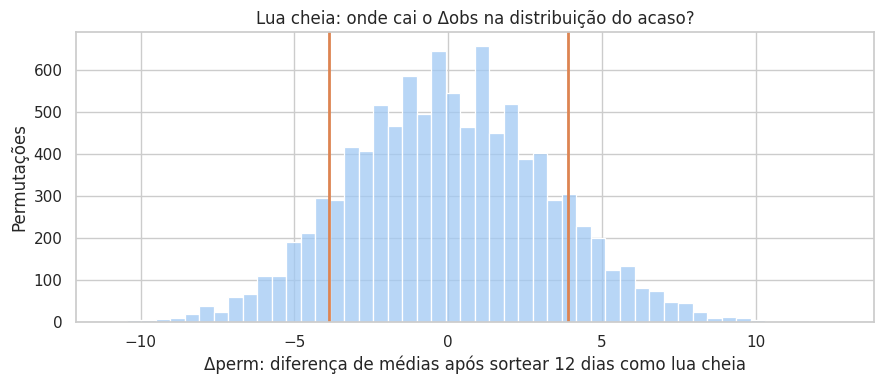

In [64]:
def plot_null(null, obs, title, xlabel):
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(null, bins=50, color="#A1C9F4", ax=ax)
    for value in [-obs, obs]:
        ax.axvline(value, color="#DD8452", linewidth=2)
    ax.set(title=title, xlabel=xlabel, ylabel="Permutações")
    plt.tight_layout()
    plt.show()

plot_null(
    moon_null,
    moon_obs,
    title="Lua cheia: onde cai o Δobs na distribuição do acaso?",
    xlabel="Δperm: diferença de médias após sortear 12 dias como lua cheia",
)

Realizando as permutações sem se limitar na quantidade de amostras, o histograma acima foi gerado, mostrando que o centro em zero confirma que nenhum grupo foi favorecido e que a largura que se estende entre +6 e -6 é a faixa que o acaso consegue produzir com 12 dias contra 353 sozinho.

In [65]:
moon_p = np.mean(np.abs(moon_null) >= abs(moon_obs))

moon_p

np.float64(0.23)

Calculando a proporção de permutações tão ou mais extremas que o observado, vemos que em 23% das permutações, dias de lua cheia apresentam mais atendimentos.

### **4.3. O p-valor**<font size=3>

O p-valor é a probabilidade, supondo que a hipótese nula é verdadeira, de obter um efeito tão ou mais extremo que o observado

### **4.4. A regra de decisão**<font size=3>

Nível de significância delimita um limiar para rejeitar ou não a estatística obtida em p-valor, rejeitando quando maior ou aceitando quando for menor.

### **4.5. Permutação no mtcars**<font size=3>

In [66]:
mpg_values = mtcars["mpg"].to_numpy()
mpg_labels = (mtcars["am"] == 1).to_numpy()

mpg_null = permutation_null(mpg_values, mpg_labels)

mpg_p = np.mean(np.abs(mpg_null) >= abs(delta_obs))

mpg_p

np.float64(0.0001)

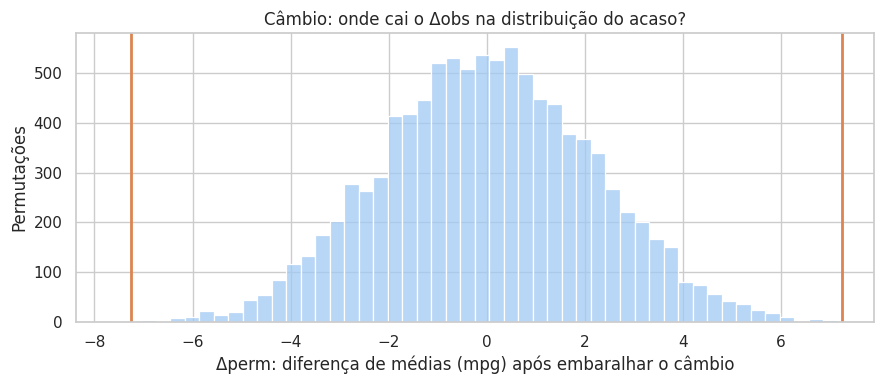

In [67]:
plot_null(
    mpg_null,
    delta_obs,
    title="Câmbio: onde cai o Δobs na distribuição do acaso?",
    xlabel="Δperm: diferença de médias (mpg) após embaralhar o câmbio",
)

Gerando um histograma que demonstra a distribuição em 10000 permutações, vemos que apenas um caso chegou a diferença de 7,24 mpg. Sendo assim, como p-valor é menor que nosso nível de siginificância, a hipótese nula é rejeitada e definimos que o câmbio importa no consumo.

## **5. O atalho paramétrico**<font size=3>

O teste paramétrico supõe que os dados seguem uma família de distribuições conhecida e usa a teoria para deduzir a distribuição nula, sendo assim, ele é feito através de três etapas: suposição do modelo, derivar a distribuição nula e ler o p-valor.

### **5.1. O erro-padrão**<font size=3>

In [68]:
round(mpg_null.std(), 2)

np.float64(2.16)

Temos a largura da distribuição nula do câmbio, ou seja, o quanto a diferença de médias oscila por acaso, medida pela simulação.

In [69]:
n_manual, n_automatic = len(manual), len(automatic)

se_null = mtcars.mpg.std() * np.sqrt(1 / n_manual + 1 / n_automatic)

round(se_null, 2)

np.float64(2.17)

Usando a fórmula que tira a raiz quadrada da variância para chegar a distribuição nula novamente, chegamos a um valor quase igual.

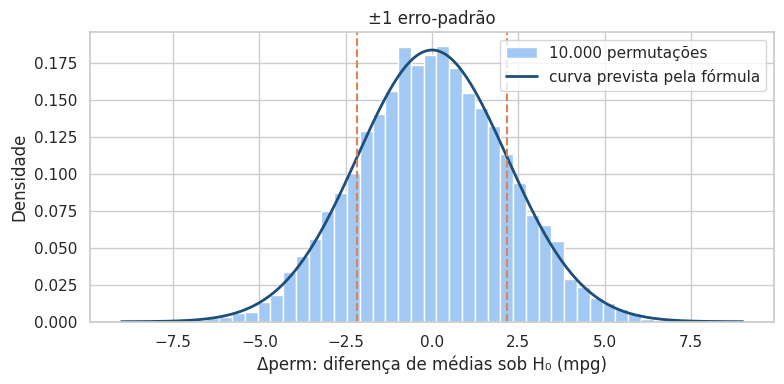

In [70]:
fig, ax = plt.subplots(figsize=(8, 4))

grid = np.linspace(-9, 9, 300)

ax.hist(mpg_null, bins=40, density=True,
        color="#A1C9F4", label="10.000 permutações")
ax.plot(grid, stats.norm.pdf(grid, 0, se_null),
        color="#1F4E79", linewidth=2, label="curva prevista pela fórmula")

for value in [-se_null, se_null]:
    ax.axvline(value, color="#DD8452", linestyle="--")

ax.set(title="±1 erro-padrão", xlabel="Δperm: diferença de médias sob H₀ (mpg)",
       ylabel="Densidade")
ax.legend()

plt.tight_layout()
plt.show()

A largura citada anteriormente é chamada de erro-padrão, funcionando como a régua do acaso, na qual as linhas tracejadas marcam um erro-padrão para cada lado de zero, e cerca de dois terços das permutações caem entre elas.

### **5.2. Desvio-padrão e erro-padrão**<font size=3>

Desvio-padrão descreve a dispersão dos dados individuais em torno da média e erro-padrão descreve a precisão da própria estimativa, dizendo o quanto a estimativa mudaria se a coleta fosse repetida com outra amostra do mesmo tamanho.

In [71]:
rng = np.random.default_rng(42)

def sample_summary(n, n_samples=2_000):
    samples = rng.choice(moon_values, size=(n_samples, n))
    return {
        "dp_dos_dados": samples.std(axis=1, ddof=1).mean(),
        "dp_das_medias": samples.mean(axis=1).std(ddof=1),
        "previsto_s_raiz_n": moon_values.std(ddof=1) / np.sqrt(n),
    }

(
    pd.DataFrame({n: sample_summary(n) for n in [10, 40, 160, 640]})
    .T
    .rename_axis("n")
    .round(2)
)

,dp_dos_dados,dp_das_medias,previsto_s_raiz_n
n,,,
10,10.64,3.54,3.45
40,10.81,1.63,1.72
160,10.87,0.89,0.86
640,10.89,0.42,0.43


Na tabela gerada acima, podemos observar individualmente cada coluna.

*   dp_dos_dados: Varia cerca de 11 atendimentos entre os dias, qualquer que seja a amostra, ou seja, coletar mais dias não torna cada dia menos variável;
*   dp_das_medias: Enquanto com 10 dias, a média varia cerca 3,5 atendimentos, temos que em 640 dias, é cerca de 0,4. Sendo assim, cada vez que quadruplica, esse valor cai pela metade;
*   previsto_s_raiz_n: Apresenta valores muito próximos da coluna anterior, confirmando a fórmula.


### **5.3. A estatística t**<font size=3>

In [72]:
round(delta_obs / se_null, 2)

np.float64(3.34)

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

In [73]:
se_welch = np.sqrt(manual.var() / n_manual + automatic.var() / n_automatic)

round(se_welch, 2), round(delta_obs / se_welch, 2)

(np.float64(1.92), np.float64(3.77))

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

In [74]:
mpg_ttest = stats.ttest_ind(manual, automatic, equal_var=False)

mpg_ttest

TtestResult(statistic=np.float64(3.767123145144923), pvalue=np.float64(0.0013736383330710345), df=np.float64(18.332251638400464))

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

In [75]:
moon_ttest = stats.ttest_ind(moon_in, moon_out, equal_var=False)

moon_ttest

TtestResult(statistic=np.float64(1.4048153658505091), pvalue=np.float64(0.1853402601391711), df=np.float64(12.043510826046889))

Um resumo das quatro transformações citadas é:



*   log: Apenas para valores positivos com boa interpretação;
*   log1p: Usada em zero e valores positivos, mantendo a boa interpretação;
*   Box-Cox: Aceita apenas valores positivos com uma interpretação menos direta;
*   Yeo-Johnson: Usada para valores de qualquer sinal, ainda com uma interpretação menos direta;

### **5.4. Premissas e limitações do teste t**<font size=3>

Um resumo das quatro transformações citadas é:



*   log: Apenas para valores positivos com boa interpretação;
*   log1p: Usada em zero e valores positivos, mantendo a boa interpretação;
*   Box-Cox: Aceita apenas valores positivos com uma interpretação menos direta;
*   Yeo-Johnson: Usada para valores de qualquer sinal, ainda com uma interpretação menos direta;

### **5.5. Um único valor atípico muda a história**<font size=3>

In [76]:
automatic_typo = pd.concat(
    [automatic, pd.Series([60.])],
    ignore_index=True,
)

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

In [77]:
def compare(group_a, group_b):
    test = stats.ttest_ind(group_a, group_b, equal_var=False)
    return {
        "dif_medias": group_a.mean() - group_b.mean(),
        "dif_medianas": group_a.median() - group_b.median(),
        "dp_automaticos": group_b.std(),
        "t": test.statistic,
        "p": test.pvalue,
    }

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

In [78]:
(
    pd.DataFrame(
        {
            "mtcars original": compare(manual, automatic),
            "+1 automático com 60 mpg": compare(manual, automatic_typo),
        }
    )
    .T
    .round(4)
)

,dif_medias,dif_medianas,dp_automaticos,t,p
mtcars original,7.2449,5.50,3.8340,3.7671,0.0014
+1 automático com 60 mpg,5.1023,5.25,10.2831,1.7805,0.0848


Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

### **5.6. Permutação e teste t**<font size=3>

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

In [79]:
(
    pd.DataFrame(
        {
            "permutação": [mpg_p, moon_p],
            "teste t (Welch)": [mpg_ttest.pvalue, moon_ttest.pvalue],
        },
        index=["mtcars", "Lua cheia"],
    )
    .round(4)
)

,permutação,teste t (Welch)
mtcars,0.0001,0.0014
Lua cheia,0.2300,0.1853


Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

## **6. Armadilhas da decisão**<font size=3>

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

### **6.1. Dois tipos de erro**<font size=3>

Um resumo das quatro transformações citadas é:



*   log: Apenas para valores positivos com boa interpretação;
*   log1p: Usada em zero e valores positivos, mantendo a boa interpretação;
*   Box-Cox: Aceita apenas valores positivos com uma interpretação menos direta;
*   Yeo-Johnson: Usada para valores de qualquer sinal, ainda com uma interpretação menos direta;

### **6.2. Muitos testes**<font size=3>

In [80]:
rng = np.random.default_rng(7)

hospital_p = stats.ttest_ind(
    rng.poisson(120, size=(20, 12)),
    rng.poisson(120, size=(20, 353)),
    axis=1,
    equal_var=False,
).pvalue

Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

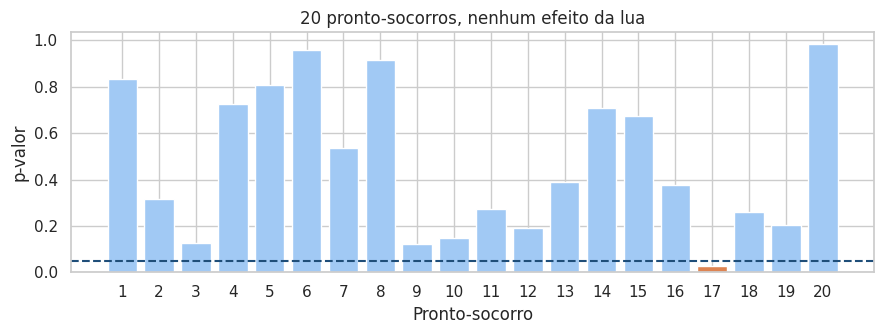

In [81]:
fig, ax = plt.subplots(figsize=(9, 3.5))

ax.bar(
    np.arange(1, 21),
    hospital_p,
    color=np.where(hospital_p <= .05, "#DD8452", "#A1C9F4"),
)
ax.axhline(.05, color="#1F4E79", linestyle="--")
ax.set(
    title="20 pronto-socorros, nenhum efeito da lua",
    xlabel="Pronto-socorro",
    ylabel="p-valor",
    xticks=np.arange(1, 21),
)

plt.tight_layout()
plt.show()

A tabela gerada acima mostra a quantidade de lacunas e os valores imputados nas colunas "hoa" e "parking_spaces".

In [82]:
alpha = .05

(
    pd.DataFrame({"k": [1, 5, 20, 100]})
    .assign(
        sem_correcao=lambda df: 1 - (1 - alpha) ** df["k"],
        bonferroni=lambda df: 1 - (1 - alpha / df["k"]) ** df["k"],
    )
    .set_index("k")
    .round(3)
)

,sem_correcao,bonferroni
k,,
1,0.050,0.050
5,0.226,0.049
20,0.642,0.049
100,0.994,0.049


Ambas as transformação alteraram a distribuição para se aproximar de uma normal, contudo, observa-se que o log1p comprime a cauda direita além do necessário, e o Yeo-Johnson estima uma transformação mais branda, porém ainda imperfeita.

### **6.3. Significância estatística não é relevância prática**<font size=3>

In [83]:
(
    pd.Series(
        {
            n: 2 * stats.t.sf(.02 * np.sqrt(n / 2), df=2 * n - 2)
            for n in [100, 1_000, 10_000, 100_000, 1_000_000]
        },
        name="p",
    )
    .rename_axis("n por grupo")
    .to_frame()
)

,p
n por grupo,
100,8.876809e-01
1000,6.547693e-01
10000,1.573148e-01
100000,7.748470e-06
1000000,2.099060e-45


Reduzimos a cauda usando logartimo para área e valores monetários, e Yeo-Johnson para a distância, que pode ser zero.

## **Para casa**<font size=3>

### **1. Adapte permutation_null para usar a diferença de medianas. Aplique-a ao cenário com o automático de 60 mpg e compare o p-valor com o do teste t da seção 5.5.**<font size=3>

### **2. Na base de imóveis da Aula 6, compare o aluguel de imóveis mobiliados e não mobiliados. Calcule DELTA de obs e o p-valor por permutação e pelo teste t. Repita a análise com o log do aluguel e discuta as diferenças.**<font size=3>

### **3. Ainda na base de imóveis, a diferença de aluguel entre mobiliados e não mobiliados poderia ser explicada por outra variável? Proponha um confundidor e verifique sua hipótese com um gráfico.**<font size=3>